# Gene embedding benchmarks: GO, OMIM, and gene pairing

This is the public, cached-first report for the validated Zhong-style gene-biology benchmark. It evaluates frozen BridgeRNA representations on GO Biological Process, OMIM disease association, and three gene-pair tasks. It also includes a static-only single-gene extension for BulkFormer-50M and BulkFormer-147M.

**Cached mode performs no model inference, SVM fitting, cross-validation, split generation, or controls.** It rebuilds all displayed summaries from compact per-term and per-fold artifacts, checks them against frozen expected tables, audits the pair splits, and regenerates the figures.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
if HERE.name != "gene_embedding_benchmarks":
    HERE = Path("notebooks/gene_embedding_benchmarks")
CACHE = HERE / "cached"
FIGURES = HERE / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

with (CACHE / "manifest.json").open() as handle:
    manifest = json.load(handle)
assert manifest["mode"].startswith("cached validated artifacts")
print(f"Cached mode: {len(manifest['files'])} validated artifacts")

Cached mode: 19 validated artifacts


## Representations and evaluation design

- **Bridge E0:** static checkpoint gene embedding, before expression encoding or transformer processing.
- **Bridge E1:** final layer-12 state under uniform `log1p(TPM)=0`; a null context, not a biological average.
- **Bridge E2:** final layer-12 state averaged across a fixed tissue-balanced panel of 200 GTEx samples.
- **BulkFormer static:** checkpoint tensor `gene_emb_onehot_layer.weight`; no BulkFormer forward inference or expression context.

For every GO or OMIM term, the RBF-SVM hyperparameter was selected using only three supplied training folds. The selected classifier was refit on all training genes and evaluated once on the untouched holdout. The headline statistic is the unweighted mean of one final held-out AUROC per term. Pair results are means across three supplied, strictly gene-disjoint outer folds.

## Single-gene GO and OMIM results

In [2]:
def summarize_terms(frame, task, model, embedding_dim):
    return {
        "Task": task, "Model": model, "N_terms": len(frame), "Embedding_dim": embedding_dim,
        "Mean_AUROC": frame.AUROC.mean(), "Median_AUROC": frame.AUROC.median(),
        "SD_AUROC": frame.AUROC.std(ddof=1), "Mean_AUPRC": frame.AUPRC.mean(),
        "Median_AUPRC": frame.AUPRC.median(), "SD_AUPRC": frame.AUPRC.std(ddof=1),
    }

single_specs = [
    ("GO", "Bridge E0", 512, "bridge_E0_GO.csv"),
    ("GO", "Bridge E1", 512, "bridge_E1_GO.csv"),
    ("GO", "Bridge E2", 512, "bridge_E2_GO.csv"),
    ("GO", "BulkFormer-50M static", 256, "bulkformer_50M_GO.csv"),
    ("GO", "BulkFormer-147M static", 640, "bulkformer_147M_GO.csv"),
    ("OMIM", "Bridge E0", 512, "bridge_E0_OMIM.csv"),
    ("OMIM", "Bridge E1", 512, "bridge_E1_OMIM.csv"),
    ("OMIM", "Bridge E2", 512, "bridge_E2_OMIM.csv"),
    ("OMIM", "BulkFormer-50M static", 256, "bulkformer_50M_OMIM.csv"),
    ("OMIM", "BulkFormer-147M static", 640, "bulkformer_147M_OMIM.csv"),
]
rows = []
for task, model, dim, filename in single_specs:
    frame = pd.read_csv(CACHE / filename)
    expected_n = 56 if task == "GO" else 103
    assert len(frame) == expected_n and frame.term.nunique() == expected_n
    assert np.isfinite(frame[["AUROC", "AUPRC"]]).all().all()
    rows.append(summarize_terms(frame, task, model, dim))
single_summary = pd.DataFrame(rows)

# Compare rebuilt summaries with the frozen research summaries.
bridge_expected = pd.read_csv(CACHE / "single_gene_expected_summary.csv")
bridge_expected["Model"] = "Bridge " + bridge_expected.Representation
bulk_expected = pd.read_csv(CACHE / "bulkformer_expected_summary.csv")
bulk_expected["Model"] = bulk_expected.Model + " static"
for expected in (bridge_expected, bulk_expected):
    merged = single_summary.merge(expected, on=["Task", "Model", "N_terms"], suffixes=("_rebuilt", "_expected"))
    assert len(merged) == len(expected)
    for metric in ["Mean_AUROC", "Median_AUROC", "SD_AUROC", "Mean_AUPRC", "Median_AUPRC", "SD_AUPRC"]:
        assert np.allclose(merged[f"{metric}_rebuilt"], merged[f"{metric}_expected"], atol=1e-12)

display(single_summary.round(4))

,Task,Model,N_terms,Embedding_dim,Mean_AUROC,Median_AUROC,SD_AUROC,Mean_AUPRC,Median_AUPRC,SD_AUPRC
0,GO,Bridge E0,56,512,0.5177,0.5156,0.0681,0.1321,0.1173,0.0627
1,GO,Bridge E1,56,512,0.7722,0.7736,0.0744,0.3668,0.3347,0.1288
2,GO,Bridge E2,56,512,0.7811,0.7876,0.0782,0.4019,0.3781,0.1391
3,GO,BulkFormer-50M static,56,256,0.6961,0.6981,0.0769,0.2579,0.2388,0.1151
4,GO,BulkFormer-147M static,56,640,0.7146,0.7119,0.0713,0.2757,0.2477,0.1181
5,OMIM,Bridge E0,103,512,0.4891,0.4950,0.1076,0.1609,0.1111,0.1328
6,OMIM,Bridge E1,103,512,0.7354,0.7438,0.1383,0.3879,0.3251,0.2232
7,OMIM,Bridge E2,103,512,0.7596,0.7536,0.1324,0.4294,0.3999,0.2330
8,OMIM,BulkFormer-50M static,103,256,0.6540,0.6419,0.1148,0.2526,0.1950,0.1667
9,OMIM,BulkFormer-147M static,103,640,0.6406,0.6423,0.1164,0.2649,0.2072,0.1738


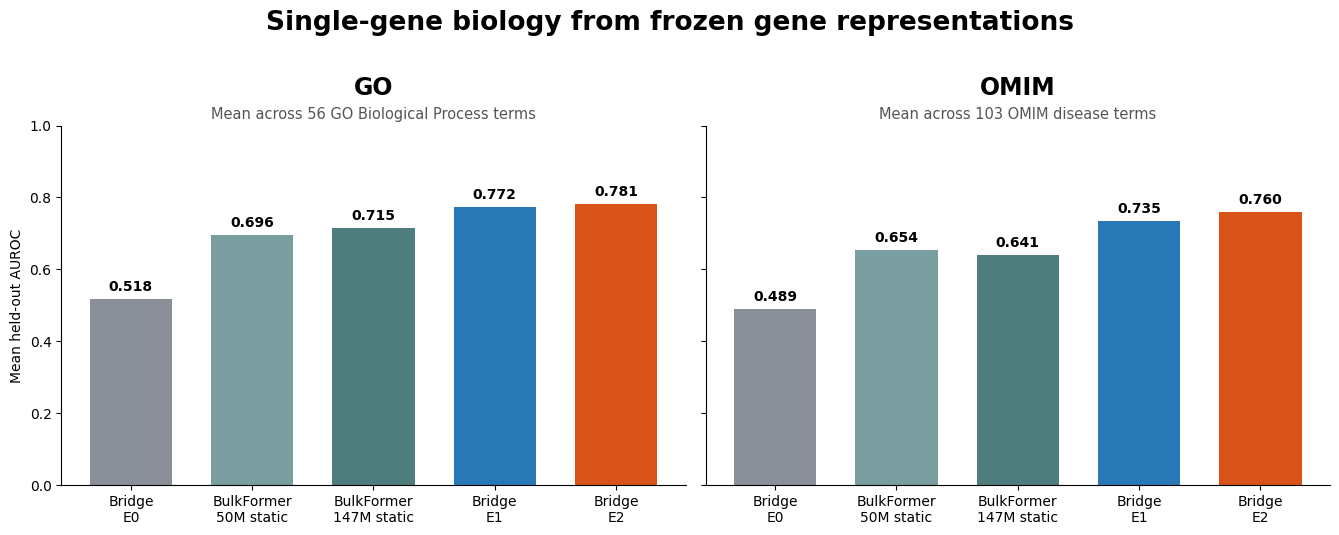

In [3]:
model_order = ["Bridge E0", "BulkFormer-50M static", "BulkFormer-147M static", "Bridge E1", "Bridge E2"]
colors = ["#8A8F98", "#7A9E9F", "#4F7C7D", "#2878B5", "#D95319"]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)
for ax, task, subtitle in zip(
    axes, ["GO", "OMIM"],
    ["Mean across 56 GO Biological Process terms", "Mean across 103 OMIM disease terms"],
):
    sub = single_summary[single_summary.Task == task].set_index("Model").loc[model_order]
    bars = ax.bar(np.arange(len(sub)), sub.Mean_AUROC, color=colors, width=0.68)
    ax.bar_label(bars, labels=[f"{value:.3f}" for value in sub.Mean_AUROC], padding=4, fontsize=10, fontweight="bold")
    ax.set_xticks(np.arange(len(sub)), ["Bridge\nE0", "BulkFormer\n50M static", "BulkFormer\n147M static", "Bridge\nE1", "Bridge\nE2"])
    ax.set_title(task, fontsize=17, fontweight="bold", pad=22)
    ax.text(0.5, 1.02, subtitle, transform=ax.transAxes, ha="center", color="#555555", fontsize=10.5)
    ax.set_ylim(0, 1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
axes[0].set_ylabel("Mean held-out AUROC")
fig.suptitle("Single-gene biology from frozen gene representations", fontsize=19, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "single_gene_go_omim.png", dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(FIGURES / "single_gene_go_omim.pdf", bbox_inches="tight", facecolor="white")
plt.show()

Bridge E1 and E2 are substantially stronger than Bridge E0, making transformer processing the dominant transition. Both BulkFormer static tables are more informative than Bridge E0, showing that a weak static result is not inevitable for bulk-transcriptome models. Bridge E1/E2 have higher mean AUROC than the tested BulkFormer static references, but this is not a formal architecture ranking because model vocabularies differ and BulkFormer was not evaluated contextually.

## Zhong literature context

In [4]:
literature = pd.read_csv(CACHE / "zhong_literature_reference.csv")
display(literature.round(4))

,Model,Input_type,GO_mean_AUROC,OMIM_mean_AUROC
0,GenePT-Model3,literature,0.9260,0.8770
1,BioConceptVec-FastText,literature,0.9090,0.8710
2,Mashup,PPI,0.8910,0.7820
3,ProtT5,amino acid,0.8450,0.6910
4,ESMB1,amino acid,0.8410,0.6850
5,scGPT-human,single-cell expression,0.7870,0.7440
6,Bridge E0,bulk-expression FM,0.5177,0.4891
7,Bridge E1,bulk-expression FM,0.7722,0.7354
8,Bridge E2,bulk-expression FM,0.7811,0.7596


The literature values above were reported by Zhong et al. and were not recomputed here. Bridge and BulkFormer use their own available vocabularies in this adaptation, so the table provides context rather than a formal head-to-head ranking.

## Gene-pair results

In [5]:
pair_folds = pd.read_csv(CACHE / "pair_outer_fold_results.csv")
assert len(pair_folds) == 81
pair_summary = (
    pair_folds.groupby(["interaction_type", "representation", "joining_operation"], as_index=False)
    .agg(outer_folds=("outer_fold", "nunique"), AUROC_mean=("AUROC", "mean"),
         AUROC_sd=("AUROC", "std"), AUPRC_mean=("AUPRC", "mean"), AUPRC_sd=("AUPRC", "std"),
         **{"Precision@10_mean": ("Precision@10", "mean"), "Precision@10_sd": ("Precision@10", "std")})
)
assert (pair_summary.outer_folds == 3).all() and len(pair_summary) == 27
pair_expected = pd.read_csv(CACHE / "pair_expected_summary.csv")
keys = ["interaction_type", "representation", "joining_operation"]
check = pair_summary.merge(pair_expected, on=keys, suffixes=("_rebuilt", "_expected"))
assert len(check) == 27
for metric in ["AUROC_mean", "AUROC_sd", "AUPRC_mean", "AUPRC_sd", "Precision@10_mean", "Precision@10_sd"]:
    assert np.allclose(check[f"{metric}_rebuilt"], check[f"{metric}_expected"], atol=1e-12)

task_labels = {"NG": "Negative genetic", "SL": "Synthetic lethal", "TF": "TF-target"}
rep_labels = {"E0_static": "E0", "E1_null_L12": "E1", "E2_GTEx200_L12": "E2"}
best = pair_summary.loc[pair_summary.groupby("interaction_type").AUROC_mean.idxmax()].copy()
best["Task"] = best.interaction_type.map(task_labels)
best["Representation"] = best.representation.map(rep_labels)
best = best.rename(columns={"joining_operation": "Pair_operation", "AUROC_mean": "AUROC", "AUPRC_mean": "AUPRC"})
best = best[["Task", "Representation", "Pair_operation", "AUROC", "AUPRC", "AUROC_sd", "AUPRC_sd"]]
best_expected = pd.read_csv(CACHE / "pair_expected_best.csv")
best_check = best.merge(best_expected, on=["Task", "Representation", "Pair_operation"], suffixes=("_rebuilt", "_expected"))
assert len(best_check) == 3
assert np.allclose(best_check.AUROC_rebuilt, best_check.AUROC_expected, atol=1e-12)

leakage = pd.read_csv(CACHE / "pair_leakage_qc.csv")
assert len(leakage) == 9 and (leakage.train_test_gene_overlap == 0).all()
display(best.round(3))
display(leakage)

,Task,Representation,Pair_operation,AUROC,AUPRC,AUROC_sd,AUPRC_sd
6,Negative genetic,E2,concat,0.580,0.133,0.028,0.024
13,Synthetic lethal,E1,product,0.707,0.228,0.122,0.137
21,TF-target,E1,concat,0.670,0.186,0.040,0.014


,task,outer_fold,train_unique_genes,test_unique_genes,train_test_gene_overlap,n_train_pairs,n_test_pairs
0,NG,0,2473,1228,0,40181,10050
1,NG,1,2456,1245,0,40597,9972
2,NG,2,2473,1228,0,39894,10157
3,SL,0,1088,549,0,7700,2105
4,SL,1,1103,534,0,8399,1810
5,SL,2,1083,554,0,7712,2125
6,TF,0,4079,2050,0,36041,9360
7,TF,1,4081,2048,0,37022,8946
8,TF,2,4098,2031,0,36544,9084


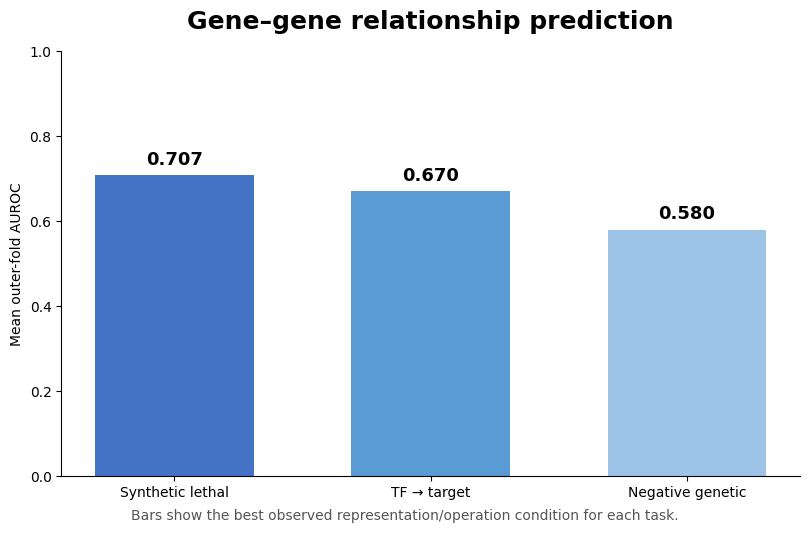

In [6]:
plot_order = ["Synthetic lethal", "TF-target", "Negative genetic"]
plot_best = best.set_index("Task").loc[plot_order]
fig, ax = plt.subplots(figsize=(8.2, 5.2))
bars = ax.bar(np.arange(3), plot_best.AUROC, color=["#4472C4", "#5B9BD5", "#9DC3E6"], width=0.62)
ax.bar_label(bars, labels=[f"{value:.3f}" for value in plot_best.AUROC], padding=5, fontsize=13, fontweight="bold")
ax.set_xticks(np.arange(3), ["Synthetic lethal", "TF → target", "Negative genetic"])
ax.set_ylim(0, 1)
ax.set_ylabel("Mean outer-fold AUROC")
ax.set_title("Gene–gene relationship prediction", fontsize=18, fontweight="bold", pad=16)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(False)
fig.text(0.5, -0.01, "Bars show the best observed representation/operation condition for each task.", ha="center", fontsize=10, color="#555555")
fig.tight_layout()
fig.savefig(FIGURES / "gene_pair_best.png", dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(FIGURES / "gene_pair_best.pdf", bbox_inches="tight", facecolor="white")
plt.show()

Synthetic-lethal and TF-target relationships are meaningfully predictable from Bridge representations, whereas negative genetic interaction prediction is weaker. E2 is not universally superior: the best synthetic-lethal and TF-target AUROCs use E1, while negative genetic interaction uses E2. BulkFormer pair tasks were not run.

## Conclusions

1. Bridge transformer-derived states encode substantially more GO and OMIM information than its static lookup table.
2. Real GTEx context provides a smaller, task-dependent improvement beyond the null-context transformer state.
3. BulkFormer static tables contain appreciable single-gene biology, but their scaling pattern is not monotonic across GO and OMIM.
4. Bridge supports generalization to unseen genes for selected pair tasks, but pair performance is task-dependent and does not imply universal relational understanding.
5. These probes establish decodability—not causal or mechanistic understanding, batch correction, or universal model superiority.

Major limitations are different available vocabularies across model families, no contextual or pair evaluation for BulkFormer, three outer folds for pair tasks, and reliance on Zhong's annotation, negative-sampling, and split design.

## Full recomputation

This public notebook intentionally uses cached artifacts. The complete expensive workflow is documented in the adjacent `README.md`. In brief, full recomputation requires the frozen checkpoints and vocabularies, Zhong's supplied split files, Bridge E0/E1 extraction, the GTEx-200 E2 inference pass, per-term GO/OMIM SVM fitting, nested gene-pair SVM fitting, and final aggregation. The BulkFormer extension reads only static checkpoint tensors. Do not launch the full workflow merely to execute this report.